# We have xarray data time and frequency, then we need to bin the data.
-> block 0 (time[0:9]), block1[10:19] ... \
-> for block zero we need to get the central time[5], block1[15] ..., this are the ticks label \
-> for each block we need to calculate the mean and STD, which goes to the ridge plot.

- perform the RFI characterization for each time bin, eg: FWHM, number the channels.

In [1]:
import h5py
import numpy as np
import xarray as xr
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib import cm, colors as mcolors



import scienceplots
plt.style.use(['science', 'no-latex'])


from pybaselines import Baseline, utils 
from scipy.signal import find_peaks
from astropy.stats import median_absolute_deviation as MAD
from astropy.modeling import models, fitting
from astropy.convolution import convolve_models


## Select the file

In [2]:
filename = ('/home/chavango/Master/DATA/SKAMPI_data/EDD_2023-03-11T14_58_01.567317UTC_ErQFG.hdf5')


# Let's porint the structure of the hdf5 file
def print_hdf5_structure(name, obj):
    indent = '  ' * name.count('/')
    if isinstance(obj, h5py.Group):
        print(f"{indent}Group: {name}")
    elif isinstance(obj, h5py.Dataset):
        print(f"{indent}Dataset: {name}, Shape: {obj.shape}, Dtype: {obj.dtype}")

with h5py.File(filename, "r") as f:

    f.visititems(print_hdf5_structure)

    f.close()  # close the file

Dataset: history, Shape: (9,), Dtype: [('processingtime', 'S23'), ('software', 'S256'), ('version', 'S128'), ('comment', 'S256')]
Group: monitor
  Group: monitor/acu
    Dataset: monitor/acu/actual_timestamp, Shape: (2650,), Dtype: float64
    Group: monitor/acu/ambient_temp_correction_config
      Dataset: monitor/acu/ambient_temp_correction_config/ambient_factor_az_band_1, Shape: (2650,), Dtype: float64
      Dataset: monitor/acu/ambient_temp_correction_config/ambient_factor_az_band_10, Shape: (2650,), Dtype: float64
      Dataset: monitor/acu/ambient_temp_correction_config/ambient_factor_az_band_2, Shape: (2650,), Dtype: float64
      Dataset: monitor/acu/ambient_temp_correction_config/ambient_factor_az_band_3, Shape: (2650,), Dtype: float64
      Dataset: monitor/acu/ambient_temp_correction_config/ambient_factor_az_band_4, Shape: (2650,), Dtype: float64
      Dataset: monitor/acu/ambient_temp_correction_config/ambient_factor_az_band_5a, Shape: (2650,), Dtype: float64
      Dataset:

In [3]:
# Convert to xarray data set
groups = [
    "scan/000/P1_ND0",
    "scan/000/P1_ND1",
    "scan/001/P0_ND0",
    "scan/001/P0_ND1",
    "scan/001/P1_ND0",
    "scan/001/P1_ND1"
]


datasets = []

with h5py.File(filename, 'r') as f:
    for g in groups:
        
        # Load datasets correctly
        spectrum  = f[f"{g}/spectrum"][30:,1600:-60]       # shape (n_time, n_freq)
        frequency = f[f"{g}/frequency"][1600:-60]/ 1e9
        time      = f[f"{g}/timestamp"][30:,0]     # often 2D


        # Construct xarray dataset
        ds = xr.Dataset(
            {
                "spectrum": (("time", "frequency"), spectrum)
            },
            coords={
                "time": time,
                "frequency": frequency
            },
            attrs={
                "description": f"Spectrum data of {g}",
                "units": {
                    "spectrum": "dB",
                    "frequency": "GHz",
                    "time": "UTC"
                }
            }
        )

        ds = ds.expand_dims({"group": [g]})  # add group dimension

        datasets.append(ds)
    f.close() # close the file

datasets

[<xarray.Dataset> Size: 163MB
 Dimensions:    (group: 1, time: 634, frequency: 63877)
 Coordinates:
   * group      (group) object 8B 'scan/000/P1_ND0'
   * time       (time) float64 5kB 1.679e+09 1.679e+09 ... 1.679e+09 1.679e+09
   * frequency  (frequency) float64 511kB 1.793 1.793 1.793 ... 3.498 3.498 3.498
 Data variables:
     spectrum   (group, time, frequency) float32 162MB 1.883e+11 ... 4.159e+09
 Attributes:
     description:  Spectrum data of scan/000/P1_ND0
     units:        {'spectrum': 'dB', 'frequency': 'GHz', 'time': 'UTC'},
 <xarray.Dataset> Size: 163MB
 Dimensions:    (group: 1, time: 634, frequency: 63877)
 Coordinates:
   * group      (group) object 8B 'scan/000/P1_ND1'
   * time       (time) float64 5kB 1.679e+09 1.679e+09 ... 1.679e+09 1.679e+09
   * frequency  (frequency) float64 511kB 1.793 1.793 1.793 ... 3.498 3.498 3.498
 Data variables:
     spectrum   (group, time, frequency) float32 162MB 6.967e+10 ... 1.648e+09
 Attributes:
     description:  Spectrum da

## Evaluate the peak variation over time.

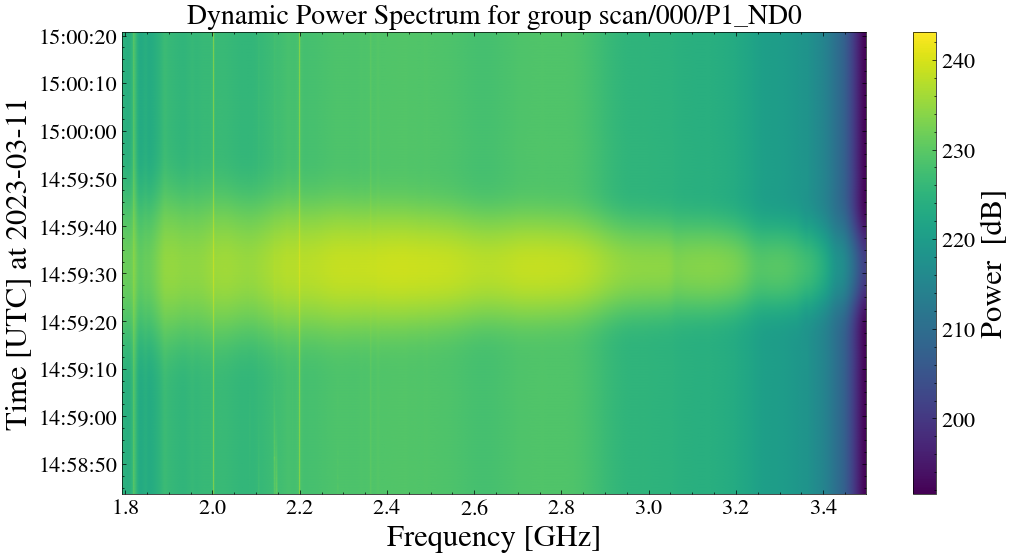

In [8]:
# define the variablues

for i,g in enumerate(datasets):
    specttrum = (10*np.log10(datasets[i]['spectrum']**2)).values[0, :,:]
    time = datasets[i]['time'].values
    frequency = datasets[i]['frequency'].values

    # Date
    time_utc = pd.to_datetime(time, unit='s', origin='unix', utc=True)
    date =  pd.to_datetime(time_utc[0].strftime('%Y-%m-%d'))


    plt.figure(figsize=(12, 6))

    plt.imshow(specttrum, aspect='auto', 
    extent=[frequency[0], frequency[-1], time_utc[0], time_utc[-1]],
    origin='lower', cmap='viridis')

    cbar = plt.colorbar()
    cbar.set_label('Power  [dB]', fontsize=22)
    cbar.ax.tick_params(labelsize=16)    
    
    plt.ylabel(f'Time [UTC] at {time_utc[0].strftime("%Y-%m-%d")}', fontsize=22)
    plt.xlabel('Frequency [GHz]', fontsize=22)
    plt.title(f'Dynamic Power Spectrum for group {datasets[i].group.values[0]}',fontsize=20)
    plt.yticks(fontsize=16)
    plt.xticks(fontsize=16)

    #plt.savefig(f'Plots/dynamic_spectrum_{time_utc[0].strftime("%Y-%m-%d")}.png', dpi=120, bbox_inches='tight')


    break

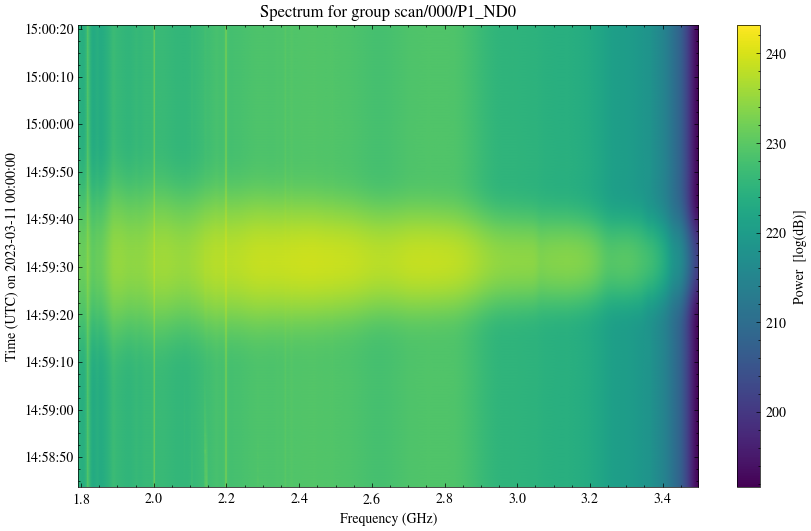

In [5]:
# define the variablues

for i,g in enumerate(datasets):
    specttrum = (10*np.log10(datasets[i]['spectrum']**2)).values[0, :,:]
    time = datasets[i]['time'].values
    frequency = datasets[i]['frequency'].values

    # Date
    time_utc = pd.to_datetime(time, unit='s', origin='unix', utc=True)
    date =  pd.to_datetime(time_utc[0].strftime('%Y-%m-%d'))


    plt.figure(figsize=(10, 6))

    plt.imshow(specttrum, aspect='auto', 
    extent=[frequency[0], frequency[-1], time_utc[0], time_utc[-1]],
    origin='lower', cmap='viridis')

    plt.colorbar(label='Power  [log(dB)]')
    plt.ylabel(f'Time (UTC) on {date}')
    plt.xlabel('Frequency (GHz)')
    plt.title(f'Spectrum for group {datasets[i].group.values[0]}')

    plt.show()

    break

### The funtions

In [6]:

# Baseline correction

def base_correction(freq,power):
    """ 
    The function perform the baseline correction using the method: "Asymmetric Least Squer"

    Takes as entries:
    --------
    freq: array
    power: array

    Returns:
    ------
    The signal with the baseline corrected
    
    """

    # Step 1: define the baseli fitting
    baseline_fitter = Baseline(x_data=freq)
    bkg, params = baseline_fitter.asls(power, lam=1e7, p=0.02)

    # Step 2: Substract the baseline
    correct_baseline = power - bkg

    return correct_baseline

#--------------------------------------------#
#                                            #
#          Characterise the RFI              #
#                                            #
#--------------------------------------------#


def characterize_RFI_width(freq, power, tie=False, ax=None, threshold=0.05):
    """
    Characterize the frequency width and fit of an RFI peak.

    Parameters
    ----------
    freq : array-like
        Frequency values [GHz].
    power : array-like
        Baseline-corrected power spectrum (linear or dB).
    tie : bool, optional
        If True, fits two tied Gaussians (narrow + broad). 
        If False, fits a single Gaussian. Default = False.
    ax : matplotlib.axes.Axes, optional
        Existing matplotlib axis for plotting.
    threshold : float, optional
        Power threshold to define start/end of RFI. Default = 0.05.

    Returns
    -------
    results : dict
        Dictionary containing:
        - start_freq [GHz]
        - end_freq [GHz]
        - peak_freq [GHz]
        - peak_power
        - n_channels
        - bandwidth [MHz]
        - fwhm [kHz]
        - fitted_model (Astropy model)
    """

    # --- 1. Identify the RFI region above threshold ---
    above_threshold = np.where(power > threshold)[0]

    if len(above_threshold) == 0:
        print(" No significant RFI detected above threshold.")
        return None

    start_index, end_index = above_threshold[0], above_threshold[-1]
    start_freq = freq[start_index]
    end_freq = freq[end_index]

    # --- 2 Find peak position and amplitude ---
    peak_index = np.argmax(power)
    peak_freq = freq[peak_index]
    peak_power = power[peak_index]

    # --- 3 Basic RFI statistics ---
    delta_f = np.mean(np.diff(freq))  # spectral resolution
    n_channels = (end_freq - start_freq) / delta_f
    bandwidth = (end_freq - start_freq) * 1e3  # GHz → MHz

    print(f"""
          Date: {pd.to_datetime(time_utc[0]).strftime('%Y-%m-%d')}
          Start Frequency  : {start_freq:.6f} GHz 
          End Frequency    : {end_freq:.6f} GHz
          Peak Frequency   : {peak_freq:.6f} GHz  | Power = {peak_power:.3f} dB
          Corrupted Channels: {n_channels:.1f}
          Corrupted Bandwidth         : {bandwidth:.2f} MHz""")

    # --- 4 Build initial Gaussian models ---
    amp_narrow = peak_power
    sigma_narrow = 5 * delta_f  # narrow Gaussian width guess

    amp_broad = amp_narrow / 5
    sigma_broad = 0.01  # GHz-scale broad Gaussian

    g_narrow = models.Gaussian1D(amplitude=amp_narrow, mean=peak_freq, stddev=sigma_narrow)
    g_broad = models.Gaussian1D(amplitude=amp_broad, mean=peak_freq, stddev=sigma_broad)

    # --- 5 Model fitting ---
    fitter = fitting.LMLSQFitter()

    if tie:
        # Tie both Gaussian centers
        def tie_means(model):
            return model.mean_0
        g_broad.mean.tied = tie_means
        model_init = g_narrow + g_broad
        fitted_model = fitter(model_init, freq, power)
        sigma = fitted_model.stddev_0.value + fitted_model.stddev_1.value
        label = "2-Gaussian Fit (tied)"
    else:
        fitted_model = fitter(g_narrow, freq, power)
        sigma = fitted_model.stddev.value
        label = "Single Gaussian Fit"

    fwhm = 2.355 * sigma  # convert σ → FWHM
    print(f"""
          Gaussian FWHM    : {fwhm * 1e6:.2f} kHz
          Number of Channels at FWHM: {np.ceil(fwhm/delta_f)}""")

    # --- 6 Plotting ---
    if ax is None:
        fig, ax = plt.subplots(figsize=(10, 5))

    ax.plot(freq, power, '.', color='steelblue', label='Data')
    ax.plot(freq, fitted_model(freq), 'black', lw=1, label=label)

    # Mark important frequencies
    ax.axvline(start_freq, color='green', ls='--', label='Start Peak')
    ax.axvline(peak_freq, color='red', ls='-', label='Peak')
    ax.axvline(end_freq, color='orange', ls='--', label='End Peak')

    ax.set_xlabel("Frequency [GHz]", fontsize=13)
    ax.set_ylabel("Power [dB]", fontsize=13)
    ax.legend(fontsize=11)
    ax.grid(alpha=0.3)

    plt.tight_layout()

    # --- 7️Return results ---
    # return {
    #     "start_freq": start_freq,
    #     "end_freq": end_freq,
    #     "peak_freq": peak_freq,
    #     "peak_power": peak_power,
    #     "n_channels": n_channels,
    #     "bandwidth_MHz": bandwidth,
    #     "fwhm_kHz": fwhm * 1e6,
    #     "fitted_model": fitted_model,
    # }


#--------------------------------------------#
#                                            #
#      Waterfall plot function for           #
#      specified frequency range             #
#                                            #
#--------------------------------------------#


def waterfall_timevsfreq(time, freq, spectrum, freq_mask, ax=None):
    """
    Generate a waterfall plot of power vs time and frequency.

    Parameters:
    time : array
        Time array in seconds since epoch.
    freq : array
        Frequency array in GHz.
    spectrum : 2D array
        Power spectrum with shape (time, frequency).
    freq_mask : boolean array
        Mask to select the frequency range of interest.
   ax : matplotlib.axes.Axes, optional
        Axis on which to draw the plot. If None, creates a new one.

    Returns:
    ax : matplotlib.axes.Axes
        The axis with the plotted data.
    """

    # --- Convert Power Spectrum to dB ---
    spectrum_db = 10 * np.log10(spectrum**2 + 1e-12)

    # Select the desired frequency channels
    power_channel = spectrum_db[:, freq_mask]

    # --- Convert Time to UTC Datetime ---
    time_utc = pd.to_datetime(time, unit="s", utc=True)
    date = pd.to_datetime(time_utc[0]).strftime('%Y-%m-%d')

    # --- Select Frequency Range (GHz) ---
    freq_sel = freq[freq_mask]

    # --- Plot Waterfall (Frequency on x, Time on y) ---

    if ax is None:
        fig, ax = plt.subplots(figsize=(12, 6))

    # --- Create Waterfall ---
    im = ax.imshow(
        power_channel,
        aspect='auto',
        origin='lower',
        extent=[freq_sel.min(), freq_sel.max(), 0, len(time_utc)],
        cmap='viridis'
    )

    # --- Colorbar ---

    cbar = plt.colorbar(im, ax=ax, label='Power [dB]')
    cbar.ax.tick_params(labelsize=14)       # set tick label size
    cbar.set_label('Power [dB]', fontsize=16)  # set label font size
    
    ax.set_xlabel('Frequency [GHz]', fontsize=16)
    ax.set_ylabel(f'Time [UTC] on {date}', fontsize=16)
    #plt.title('Waterfall Plot: Time vs Frequency', fontsize=18)

    # --- Y-axis: Time Ticks (UTC) ---
    n_ticks = 10
    tick_positions = np.linspace(0, len(time_utc) - 1, n_ticks, dtype=int)
    tick_labels = [time_utc[i].strftime("%H:%M:%S") for i in tick_positions]

    ax.set_yticks(tick_positions)
    ax.set_yticklabels(tick_labels)

    # --- X-axis: Frequency ---
    ax.set_xlim(freq_sel.min(), freq_sel.max())
    ax.grid(False)


#--------------------------------------------#
#                                            #
#        Ridge RFI Characterization          #
#                                            #
#--------------------------------------------#



def ridgeplot_rfi_characterization(time_utc, frequency, spectrum, mask=None, n_samples=10, threshold=0.05, ax=None):
    """
    Create a ridge plot of spectra vs frequency and characterize RFI features
    at selected time steps.
    """
    # --- Apply mask if provided ---
    if mask is not None:
        freq = frequency[mask]
        spec = spectrum[:, mask]
    else:
        freq = frequency
        spec = spectrum

    n_time = spec.shape[0]
    idx = np.linspace(0, n_time - 1, n_samples, dtype=int)

    # Compute mean power per spectrum for colormap
    mean_power = [10 * np.log10(np.nanmean(spec[k, :]**2)) for k in idx]
    norm = plt.Normalize(min(mean_power), max(mean_power))
    colors = cm.plasma(norm(mean_power))

    #Date
    time = pd.to_datetime(time_utc, unit='s', utc=True)
    date=pd.to_datetime(time[0]).strftime('%Y-%m-%d')

    # --- Create Figure ---
    if ax is None:
        fig, ax = plt.subplots(figsize=(10, 8))

    print(f"\n === RFI CHARACTERIZATION PER TIME STEP on: {date} ===")
    print(f"Using threshold: {threshold:.3f}\n")

    for i, (k, color) in enumerate(zip(idx, colors)):
        y = spec[k, :]
        y_db = 10 * np.log10(y**2 + 1e-12)  # Convert to dB, avoid log(0)
        y_norm = (y_db - np.nanmean(y_db)) / np.nanstd(y_db)
        offset = i * 2.0

        # --- Plot ridge ---
        ax.plot(freq, y_norm + offset, color=color, lw=1.2)
        ax.fill_between(freq, offset, y_norm + offset, color=color, alpha=0.4)

        # --- RFI characterization ---
        above_threshold = np.where(y_db > threshold)[0]
        if len(above_threshold) > 0:
            start_index, end_index = above_threshold[0], above_threshold[-1]
            start_freq = freq[start_index]
            end_freq = freq[end_index]
            peak_index = np.argmax(y_db)
            peak_freq = freq[peak_index]
            peak_power = y_db[peak_index]

            delta_f = np.mean(np.diff(freq))  # channel width
            n_channels = (end_freq - start_freq) / delta_f
            bandwidth = (end_freq - start_freq) * 1e3  # GHz → MHz

            print(f"[{time[k].strftime('%H:%M:%S')}]  "
                  f"Peak: {peak_freq:.6f} GHz | Power: {peak_power:.3f} dB | "
                  f"BW: {bandwidth:.2f} MHz | Channels: {n_channels:.1f}")
        else:
            print(f"[{time[k].strftime('%H:%M:%S')}]  No RFI detected above threshold.")

    # colorbar to interoret variation
    sm=cm.ScalarMappable(cmap=cm.plasma, norm=norm)
    sm.set_array([])
    cbar=plt.colorbar(sm,ax=ax, label='Mean Power ')

    # --- Y-axis: Time Labels (UTC) ---
    n_ticks = min(10, n_samples)
    tick_positions = np.linspace(0, n_samples - 1, n_ticks, dtype=int)
    tick_labels = [time[i].strftime("%H:%M:%S") for i in tick_positions]

    ax.set_yticks(tick_positions * 2.0)
    ax.set_yticklabels(tick_labels, fontsize=9)
    ax.set_ylabel(f"Time [UTC] on {date}", fontsize=11)

    # --- X-axis ---
    ax.set_xlabel("Frequency [GHz]", fontsize=11)
    ax.set_title("RFI variation over the Observation", fontsize=13)
    ax.grid(alpha=0.3)

    plt.tight_layout()



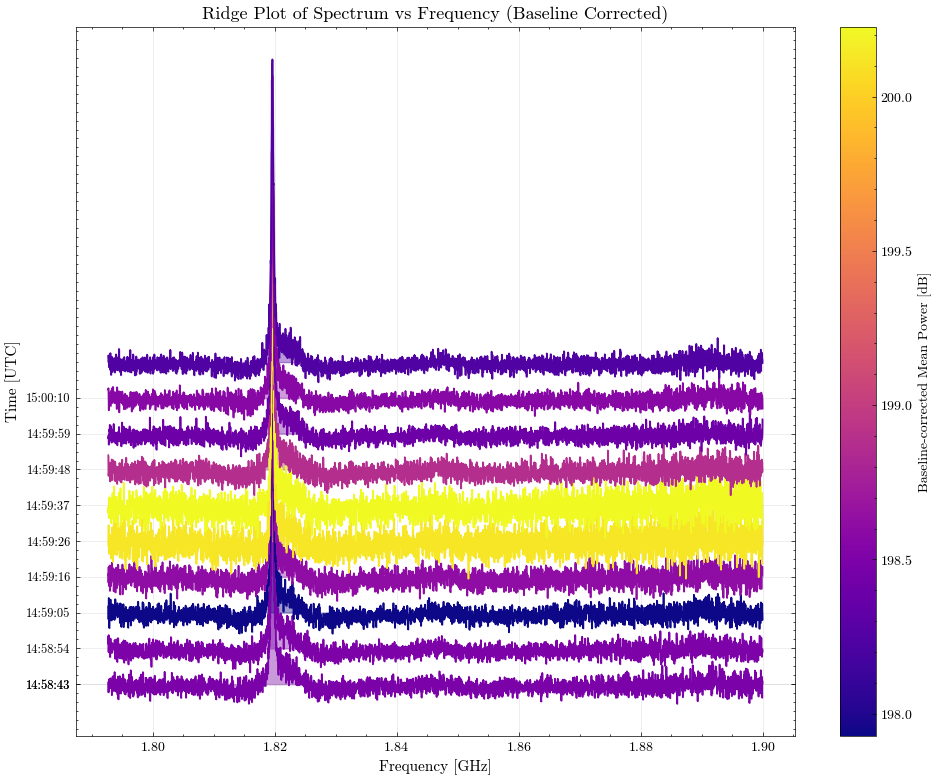

In [7]:
mask = (frequency > 2.00) & (frequency < 2.007)

mask1 = (frequency > 1.7) & (frequency < 1.9)

# --- Extract subset ---
freq = frequency[mask1]
spec = spectrum[:, mask1]

n_time, n_freq = spec.shape

# --- Configuration ---
n_samples = 10  # number of ridges to show
idx = np.linspace(0, n_time - 1, n_samples, dtype=int) # Just creat an array of indices

# --- Compute detrended (baseline-corrected) power for color normalization ---
det_power = []
mean_spectra = []

for k in idx:
    # selected spectrum at time k
    select_spec = (spec[k, :])
    
    # --- Apply baseline correction ---
    corrected_spectrum = base_correction(freq, select_spec)
    mean_spectra.append(corrected_spectrum)
    
    # Compute power in dB after correction
    pwr = 10 * np.log10(np.nanmean(corrected_spectrum**2))
    det_power.append(pwr)

# --- Normalize color map according to corrected power ---
norm = plt.Normalize(vmin=np.min(det_power), vmax=np.max(det_power))
colors = cm.plasma(norm(det_power))

# --- Create figure ---
fig, ax = plt.subplots(figsize=(10, 8))

for i, (y, color) in enumerate(zip(mean_spectra, colors)):
    # Normalize each corrected spectrum for ridge shape visualization
    y_norm = (y - np.nanmean(y)) / np.nanstd(y)
    
    # Vertical offset per ridge
    offset = i * 2.0
    
    # --- Plot ridge ---
    ax.plot(freq, y_norm + offset, color=color, lw=1.2)
    ax.fill_between(freq, offset, y_norm + offset, color=color, alpha=0.4)

# --- Colorbar for power interpretation ---
sm = cm.ScalarMappable(cmap=cm.plasma, norm=norm)
sm.set_array([])
cbar = plt.colorbar(sm, ax=ax, label='Baseline-corrected Mean Power [dB]')

 #Date
time = pd.to_datetime(time_utc, unit='s', utc=True)
date=pd.to_datetime(time[0]).strftime('%Y-%m-%d')

# --- Y-axis: Time labels (UTC) ---
n_ticks = min(10, n_samples)
tick_positions = np.linspace(0, n_samples - 2, n_ticks, dtype=int)
tick_labels = [time[idx[i]].strftime("%H:%M:%S") for i in tick_positions]

ax.set_yticks(tick_positions * 2.0)
ax.set_yticklabels(tick_labels, fontsize=9)
ax.set_ylabel("Time [UTC]", fontsize=11)

# --- X-axis and aesthetics ---
ax.set_xlabel("Frequency [GHz]", fontsize=11)
ax.set_title("Ridge Plot of Spectrum vs Frequency (Baseline Corrected)", fontsize=13)
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()


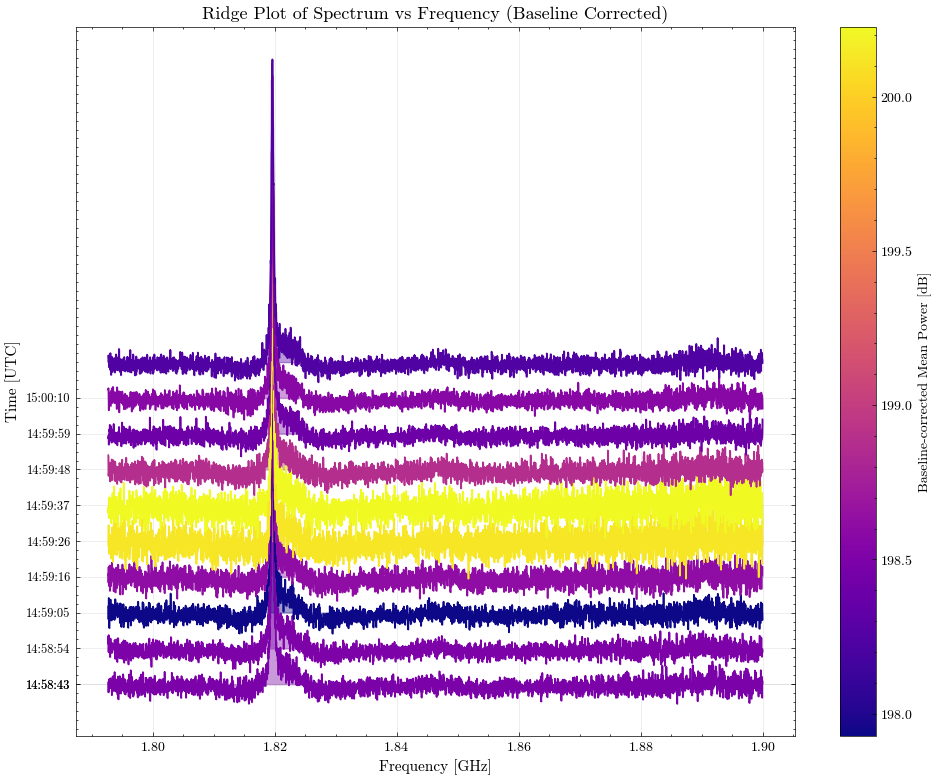

In [8]:
# Using the detrend signal


# --- Normalize color map according to corrected power ---
norm = plt.Normalize(vmin=np.min(det_power), vmax=np.max(det_power))
colors = cm.plasma(norm(det_power))

# --- Create figure ---
fig, ax = plt.subplots(figsize=(10, 8))

for i, (y, color) in enumerate(zip(mean_spectra, colors)):
    # Normalize each corrected spectrum for ridge shape visualization
    y_norm = (y - np.nanmean(y)) / np.nanstd(y)
    
    # Vertical offset per ridge
    offset = i * 2.0
    
    # --- Plot ridge ---
    ax.plot(freq, y_norm + offset, color=color, lw=1.2)
    ax.fill_between(freq, offset, y_norm + offset, color=color, alpha=0.4)

# --- Colorbar for power interpretation ---
sm = cm.ScalarMappable(cmap=cm.plasma, norm=norm)
sm.set_array([])
cbar = plt.colorbar(sm, ax=ax, label='Baseline-corrected Mean Power [dB]')

 #Date
time = pd.to_datetime(time_utc, unit='s', utc=True)
date=pd.to_datetime(time[0]).strftime('%Y-%m-%d')

# --- Y-axis: Time labels (UTC) ---
n_ticks = min(10, n_samples)
tick_positions = np.linspace(0, n_samples - 2, n_ticks, dtype=int)
tick_labels = [time[idx[i]].strftime("%H:%M:%S") for i in tick_positions]

ax.set_yticks(tick_positions * 2.0)
ax.set_yticklabels(tick_labels, fontsize=9)
ax.set_ylabel("Time [UTC]", fontsize=11)

# --- X-axis and aesthetics ---
ax.set_xlabel("Frequency [GHz]", fontsize=11)
ax.set_title("Ridge Plot of Spectrum vs Frequency (Baseline Corrected)", fontsize=13)
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()


In [9]:

n_time, n_freq = spectrum.shape
block_size = 63
blocks = []

# Step through the array in increments of 63
for start in range(0, n_time - block_size + 1, block_size):
    end = start + block_size
    block = spectrum[start:end, :]   # shape: (63, 63877)
    blocks.append(block)

blocks = np.array(blocks)  # shape: (n_blocks, 63, 63877)

print("Number of blocks:", blocks.shape[0])
print("Blocks shape:", blocks.shape)


Number of blocks: 10
Blocks shape: (10, 63, 63877)


Blocks shape: (10, 63, 63877)


/tmp/ipykernel_1734687/473522038.py:45: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = plt.cm.get_cmap('plasma')


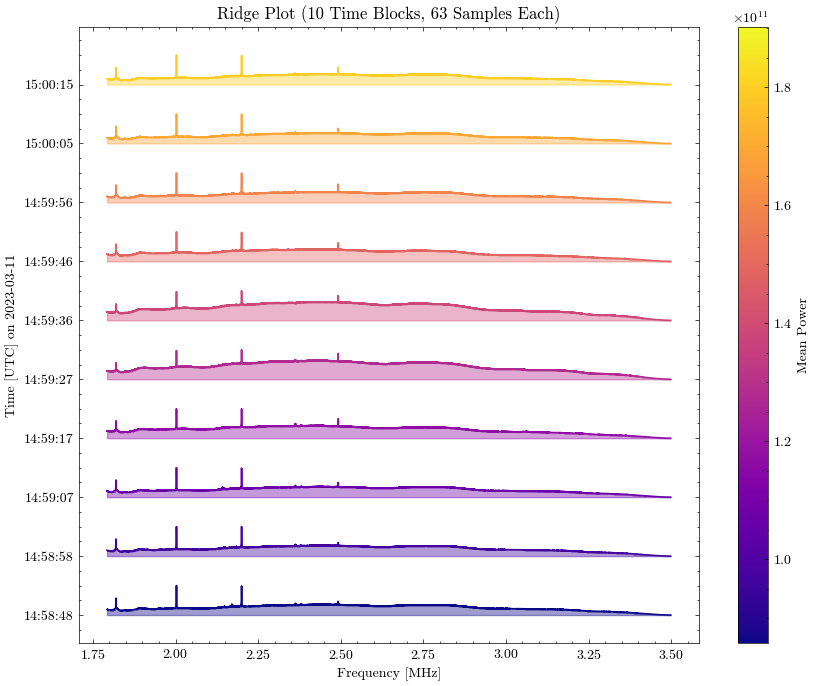

In [10]:
# import numpy as np
# import pandas as pd
# import matplotlib.pyplot as plt
# from matplotlib import cm, colors as mcolors

# -----------------------------
# 1. SPLIT INTO 10 BLOCKS
# -----------------------------
n_time, n_freq = spectrum.shape
block_size = 63
blocks = []

for start in range(0, n_time - block_size + 1, block_size):
    end = start + block_size
    block = spectrum[start:end, :]     # shape (63, 63877)
    blocks.append(block)


blocks = np.array(blocks)              # shape (10, 63, 63877)
n_blocks = blocks.shape[0]

print("Blocks shape:", blocks.shape)

# -----------------------------
# 2. AVERAGE EACH BLOCK
# -----------------------------
ridge_spectra = blocks.mean(axis=1)    # shape (10, 63877)

# -----------------------------
# 3. TIME FOR EACH BLOCK
# -----------------------------
# Convert time_utc to datetime
time_dt = pd.to_datetime(time_utc, unit='s', utc=True)

# Center of each block (use middle row)
center_idx = block_size // 2
time_binned = time_dt[center_idx::block_size]   # length = 10
date = time_binned[0].strftime('%Y-%m-%d')

# -----------------------------
# 4. RIDGE PLOT
# -----------------------------
fig, ax = plt.subplots(figsize=(10, 8))

cmap = plt.cm.get_cmap('plasma')

for i in range(n_blocks):
    offset = i * 2.0

    # normalize spectrum
    y = ridge_spectra[i]
    y_norm = y - y.min()
    y_norm = y_norm / y_norm.max()

    color = cmap(i / n_blocks)

    # plot
    ax.plot(frequency, y_norm + offset, color=color, lw=1.2)
    ax.fill_between(frequency, offset, y_norm + offset, color=color, alpha=0.4)

# -----------------------------
# 5. COLORBAR
# -----------------------------
mean_power = ridge_spectra.mean(axis=1)
norm = mcolors.Normalize(vmin=mean_power.min(), vmax=mean_power.max())
sm = cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array(mean_power)
plt.colorbar(sm, ax=ax, label='Mean Power')

# -----------------------------
# 6. Y-AXIS TIME LABELS
# -----------------------------
n_ticks = min(10, n_blocks)
tick_positions = np.linspace(0, n_blocks - 1, n_ticks, dtype=int)
tick_labels = [time_binned[i].strftime("%H:%M:%S") for i in tick_positions]

ax.set_yticks(tick_positions * 2.0)
ax.set_yticklabels(tick_labels)
ax.set_ylabel(f"Time [UTC] on {date}")

# -----------------------------
# 7. LABELS & TITLE
# -----------------------------
ax.set_xlabel("Frequency [MHz]")
ax.set_title("Ridge Plot (10 Time Blocks, 63 Samples Each)")

plt.show()


In [11]:
# Devide the data in different time blocks and average each block over time.a

block_size = 63

blocks1 = []

blocks1_det = []

for start in range(0, n_time - block_size + 1, block_size):
    end = start + block_size 
    block = spectrum[start:end, :]     # shape (63, 63877)


    # averarege the block and convert in [dB]
    block_mean = 10*np.log10(np.nanmean(block**2, axis=0))
    blocks1.append(block_mean)

    # detrend the blocks
    blocks_det = base_correction(frequency, block_mean)
    blocks1_det.append(blocks_det)

    #break

# convert to an array
blocks1 = np.array(blocks1) 
blocks1_det = np.array(blocks1_det) 

print(blocks1.shape)
print(blocks1_det.shape)


(10, 63877)
(10, 63877)


In [12]:
center_idx = block_size // 2
time_binned = time[center_idx::block_size]   # length = 10
block_time = time_binned.strftime("%H:%M:%S")
block_time = np.array(block_time)
print(block_time)

['14:58:48' '14:58:58' '14:59:07' '14:59:17' '14:59:27' '14:59:36'
 '14:59:46' '14:59:56' '15:00:05' '15:00:15']


/tmp/ipykernel_1734687/421167678.py:26: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = plt.cm.get_cmap('plasma')


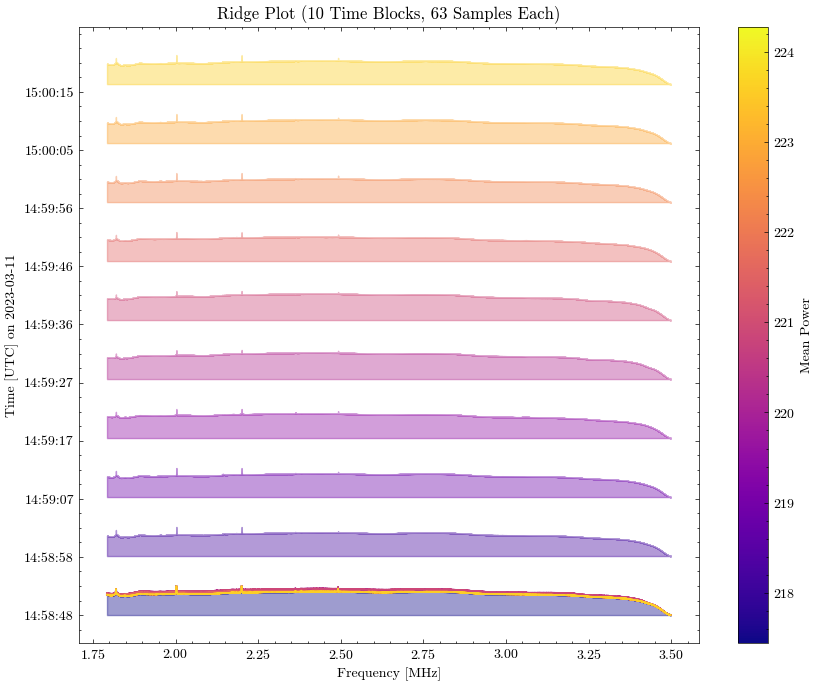

In [13]:


# print(f"""
#     Blocks shape: {blocks.shape}
#     Blocks_det shape: {blocks1_det}""")

# -----------------------------
# 2. AVERAGE EACH BLOCK
# -----------------------------
ridge_spectra = blocks1   # shape (10, 63877)

# -----------------------------
# 3. TIME FOR EACH BLOCK
# -----------------------------
# Convert time_utc to datetime
time_dt = pd.to_datetime(time_utc, unit='s', utc=True)

# Center of each block (use middle row)
center_idx = block_size // 2
time_binned = time_dt[center_idx::block_size]   # length = 10
date = time_binned[0].strftime('%Y-%m-%d')

# -----------------------------
# 4. RIDGE PLOT
# -----------------------------
fig, ax = plt.subplots(figsize=(10, 8))

cmap = plt.cm.get_cmap('plasma')

for i in range(n_blocks):
    offset = i * 2.03
    
    # normalize spectrum
    y = ridge_spectra[i]
    y_norm = y - y.min()
    y_norm = y_norm / y_norm.max()

    color = cmap(i / n_blocks)

    # plot
    ax.plot(frequency, y_norm, color=color, lw=1.2)
    ax.fill_between(frequency, offset, y_norm + offset, color=color, alpha=0.4)

# -----------------------------
# 5. COLORBAR
# -----------------------------
mean_power = ridge_spectra.mean(axis=1)
norm = mcolors.Normalize(vmin=mean_power.min(), vmax=mean_power.max())
sm = cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array(mean_power)
plt.colorbar(sm, ax=ax, label='Mean Power')

# -----------------------------
# 6. Y-AXIS TIME LABELS
# -----------------------------
n_ticks = min(10, n_blocks)
tick_positions = np.linspace(0, n_blocks - 1, n_ticks, dtype=int)
tick_labels = [time_binned[i].strftime("%H:%M:%S") for i in tick_positions]

ax.set_yticks(tick_positions * 2.0)
ax.set_yticklabels(tick_labels)
ax.set_ylabel(f"Time [UTC] on {date}")

# -----------------------------
# 7. LABELS & TITLE
# -----------------------------
ax.set_xlabel("Frequency [MHz]")
ax.set_title("Ridge Plot (10 Time Blocks, 63 Samples Each)")

plt.show()


In [14]:
blocks1[0]

array([216.99455, 217.02856, 216.98071, ..., 184.78265, 184.77115,
       184.77989], dtype=float32)

In [15]:

# # -----------------------------
# # 1. SPLIT INTO 10 BLOCKS
# # -----------------------------
# n_time, n_freq = spectrum.shape
# block_size = 63
# blocks = []
# blocks_det = []

# for start in range(0, n_time - block_size + 1, block_size):
#     end = start + block_size
#     block = spectrum[start:end, :]     # shape (63, 63877)
#     blocks.append(block)

#     # averarege the block and convert in [dB]
#     block_mean = 10*np.log10(np.mean(block**2, axis=0))
#     blocks.append(block_mean)

#     # detrend the blocks
#     blocks_det = base_correction(frequency, block_mean)
#     blocks_det.append(blocks_det)



# # convert to an array
# blocks = np.array(blocks)              # shape (10, 63, 63877)
# blocks_det= np.array(blocks_det)
# n_blocks = blocks.shape[0]

# print(f"""
#     Blocks shape: {blocks.shape}
#     Blocks_det shape: {blocks1_det}""")

# # -----------------------------
# # 2. AVERAGE EACH BLOCK
# # -----------------------------
# ridge_spectra = blocks.mean(axis=1)    # shape (10, 63877)

# # -----------------------------
# # 3. TIME FOR EACH BLOCK
# # -----------------------------
# # Convert time_utc to datetime
# time_dt = pd.to_datetime(time_utc, unit='s', utc=True)

# # Center of each block (use middle row)
# center_idx = block_size // 2
# time_binned = time_dt[center_idx::block_size]   # length = 10
# date = time_binned[0].strftime('%Y-%m-%d')

# # -----------------------------
# # 4. RIDGE PLOT
# # -----------------------------
# fig, ax = plt.subplots(figsize=(10, 8))

# cmap = plt.cm.get_cmap('plasma')

# for i in range(n_blocks):
#     offset = i * 2.0

#     # normalize spectrum
#     y = ridge_spectra[i]
#     y_norm = y - y.min()
#     y_norm = y_norm / y_norm.max()

#     color = cmap(i / n_blocks)

#     # plot
#     ax.plot(frequency, y_norm + offset, color=color, lw=1.2)
#     ax.fill_between(frequency, offset, y_norm + offset, color=color, alpha=0.4)

# # -----------------------------
# # 5. COLORBAR
# # -----------------------------
# mean_power = ridge_spectra.mean(axis=1)
# norm = mcolors.Normalize(vmin=mean_power.min(), vmax=mean_power.max())
# sm = cm.ScalarMappable(cmap=cmap, norm=norm)
# sm.set_array(mean_power)
# plt.colorbar(sm, ax=ax, label='Mean Power')

# # -----------------------------
# # 6. Y-AXIS TIME LABELS
# # -----------------------------
# n_ticks = min(10, n_blocks)
# tick_positions = np.linspace(0, n_blocks - 1, n_ticks, dtype=int)
# tick_labels = [time_binned[i].strftime("%H:%M:%S") for i in tick_positions]

# ax.set_yticks(tick_positions * 2.0)
# ax.set_yticklabels(tick_labels)
# ax.set_ylabel(f"Time [UTC] on {date}")

# # -----------------------------
# # 7. LABELS & TITLE
# # -----------------------------
# ax.set_xlabel("Frequency [MHz]")
# ax.set_title("Ridge Plot (10 Time Blocks, 63 Samples Each)")

# plt.show()


In [16]:
637//10

63

/tmp/ipykernel_1734687/4253809998.py:2: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  colors = plt.cm.get_cmap(cmap, n_blocks)
/home/chavango/anaconda3/envs/SKAMPIDATA/lib/python3.9/site-packages/IPython/core/pylabtools.py:152: UserWarning: Glyph 8594 (\N{RIGHTWARDS ARROW}) missing from font(s) cmr10.
  fig.canvas.print_figure(bytes_io, **kw)


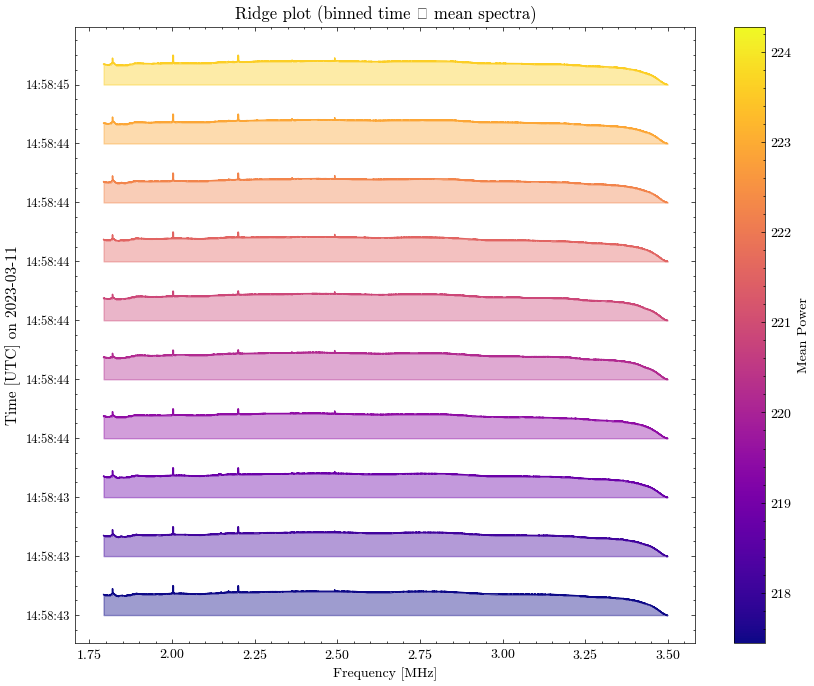

In [17]:

n_blocks = ridge_spectra.shape[0]
colors = plt.cm.get_cmap(cmap, n_blocks)

fig, ax = plt.subplots(figsize=(10, 8))

# Plot ridge spectra
for i in range(n_blocks):
    offset = i * 2.0
    y = ridge_spectra[i] - ridge_spectra[i].min()
    y = y / y.max()  # normalize
    ax.plot(frequency, y + offset, color=colors(i / n_blocks))
    ax.fill_between(frequency, offset, y + offset, color=colors(i / n_blocks), alpha=0.4)

# Colorbar for mean power
mean_power = ridge_spectra.mean(axis=1)
norm = mcolors.Normalize(vmin=mean_power.min(), vmax=mean_power.max())
sm = cm.ScalarMappable(cmap=cm.plasma, norm=norm)
sm.set_array(mean_power)
cbar = plt.colorbar(sm, ax=ax, label='Mean Power')

# Time / Date
time = pd.to_datetime(time_utc, unit='s', utc=True)
date = pd.to_datetime(time[0]).strftime('%Y-%m-%d')

# Y-axis ticks
n_ticks = min(10, n_blocks)
tick_positions = np.linspace(0, n_blocks - 1, n_ticks, dtype=int)
tick_labels = [time[i].strftime("%H:%M:%S") for i in tick_positions]

ax.set_yticks(tick_positions * 2.0)
ax.set_yticklabels(tick_labels, fontsize=9)
ax.set_ylabel(f"Time [UTC] on {date}", fontsize=11)

ax.set_xlabel("Frequency [MHz]")
ax.set_title("Ridge plot (binned time → mean spectra)")
plt.show()


In [18]:
len(time)//10

63

In [19]:
n_blocks

10

Ridge spectra shape: (10, 63877)


/tmp/ipykernel_1734687/897239595.py:24: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  colors = plt.cm.get_cmap('plasma', n_blocks)  # choose colormap
/home/chavango/anaconda3/envs/SKAMPIDATA/lib/python3.9/site-packages/IPython/core/pylabtools.py:152: UserWarning: Glyph 8594 (\N{RIGHTWARDS ARROW}) missing from font(s) cmr10.
  fig.canvas.print_figure(bytes_io, **kw)


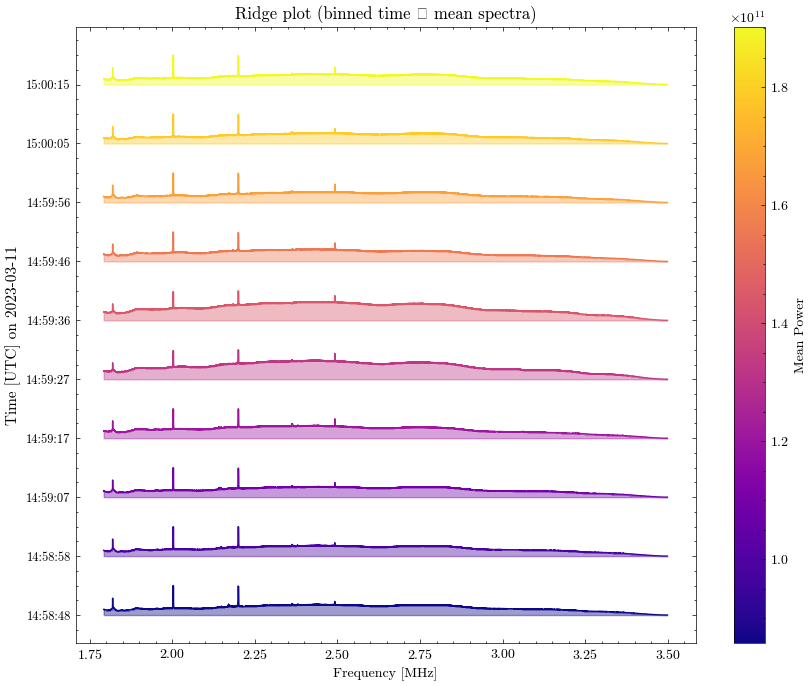

In [20]:

# -------------------------------
# Inputs
# -------------------------------
n_time, n_freq = spectrum.shape
bin_size = len(time)//10   # time points per ridge line

# 1. Trim time axis so it's divisible by bin_size
binned_size = (n_time // bin_size) * bin_size
spectrum_trimmed = spectrum[:binned_size, :]
time_trimmed = time_utc[:binned_size]

# 2. Reshape into blocks
spectrum_reshaped = spectrum_trimmed.reshape(-1, bin_size, n_freq)

# 3. Average within each block
ridge_spectra = spectrum_reshaped.mean(axis=1)
n_blocks = ridge_spectra.shape[0]

print("Ridge spectra shape:", ridge_spectra.shape)

# -------------------------------
# Ridge plot
# -------------------------------
colors = plt.cm.get_cmap('plasma', n_blocks)  # choose colormap
fig, ax = plt.subplots(figsize=(10, 8))

for i in range(n_blocks):
    offset = i * 2.0
    y = ridge_spectra[i] - ridge_spectra[i].min()
    y = y / y.max()  # normalize
    ax.plot(frequency, y + offset, color=colors(i / n_blocks))
    ax.fill_between(frequency, offset, y + offset, color=colors(i / n_blocks), alpha=0.4)

# Colorbar for mean power
mean_power = ridge_spectra.mean(axis=1)
norm = mcolors.Normalize(vmin=mean_power.min(), vmax=mean_power.max())
sm = cm.ScalarMappable(cmap=cm.plasma, norm=norm)
sm.set_array(mean_power)
cbar = plt.colorbar(sm, ax=ax, label='Mean Power')

# -------------------------------
# Time labels (binned)
# -------------------------------time_trimmed = pd.to_datetime(time_utc[:binned_size], unit='s', utc=True)

# Pick center time of each block
center_idx = bin_size // 2
time_binned = time_trimmed[center_idx::bin_size]  # take the center of each block

date = time_binned[0].strftime('%Y-%m-%d')

# Y-axis ticks
n_ticks = min(10, n_blocks)
tick_positions = np.linspace(0, n_blocks - 1, n_ticks, dtype=int)
tick_labels = [time_binned[i].strftime("%H:%M:%S") for i in tick_positions]

ax.set_yticks(tick_positions * 2.0)
ax.set_yticklabels(tick_labels, fontsize=9)
ax.set_ylabel(f"Time [UTC] on {date}", fontsize=11)
ax.set_xlabel("Frequency [MHz]")
ax.set_title("Ridge plot (binned time → mean spectra)")
plt.show()


# Characterize the RFI peak at 2.00GHz for the all blocks.
-> Whrit about the limitations/desavantage of detrending on the RFI characterization

with the strong backgroud how does it afect the amplitude.

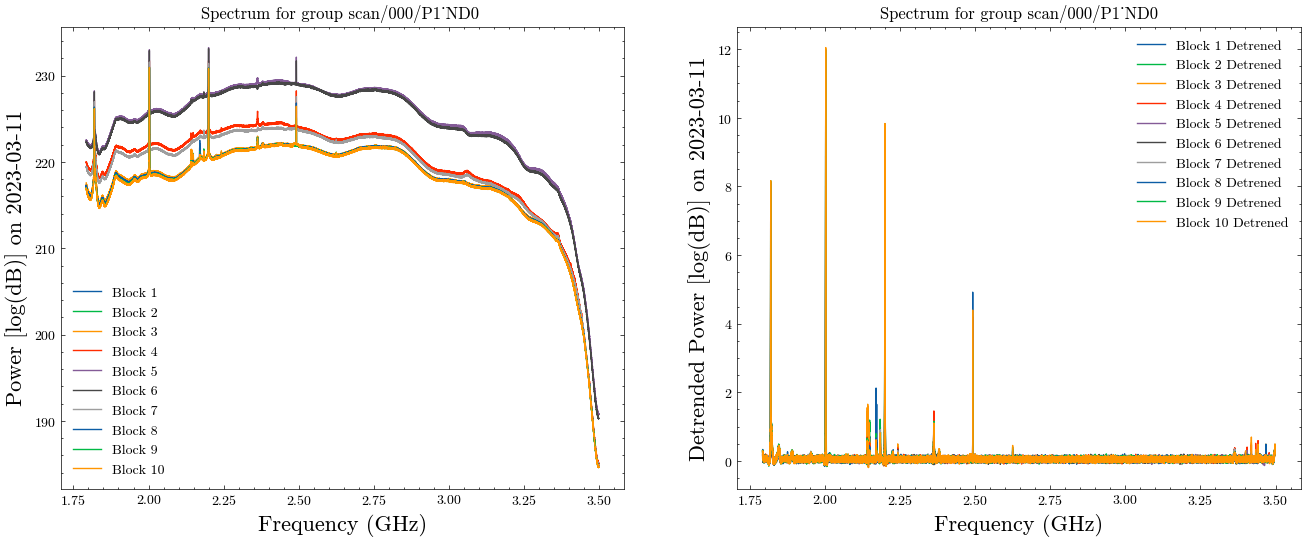

In [21]:
fig,ax=plt.subplots(1,2,figsize=(16,6))
for i,g in enumerate(blocks1):

    ax[0].plot(frequency,blocks1[i],label=f'Block {i+1}')
    ax[0].set_ylabel(f'Power [log(dB)] on {date}',fontsize=16)
    ax[0].set_xlabel('Frequency (GHz)',fontsize=16)
    ax[0].set_title(f'Spectrum for group {datasets[0].group.values[0]} ')
    ax[0].legend()
    ax[0].grid()


    #Detrended signal of the blocks
    ax[1].plot(frequency,blocks1_det[i],label=f'Block {i+1} Detrened')
    ax[1].set_ylabel(f'Detrended Power [log(dB)] on {date}',fontsize=16)
    ax[1].set_xlabel('Frequency (GHz)', fontsize=16)
    ax[1].set_title(f'Spectrum for group {datasets[0].group.values[0]}')
    ax[1].legend()
    ax[1].grid()


    #break

*pseudo*, where we have the strong RFI we replace with the nearete value befero raising on the nondetrended signal.


          Date: 2023-03-11
          Start Frequency  : 2.000059 GHz 
          End Frequency    : 2.005079 GHz
          Peak Frequency   : 2.002783 GHz  | Power = 11.980 dB
          Corrupted Channels: 188.0
          Corrupted Bandwidth         : 5.02 MHz

          Gaussian FWHM    : 1070.99 kHz
          Number of Channels at FWHM: 41.0


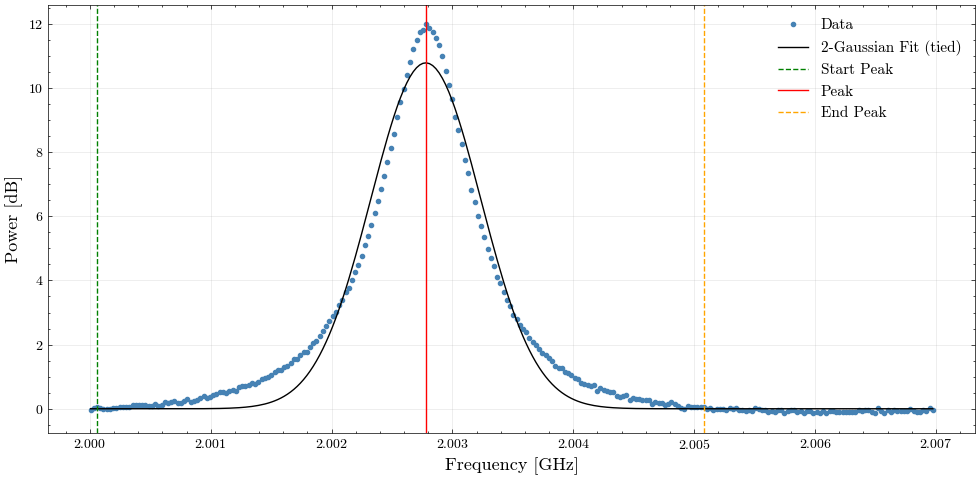

In [22]:
characterize_RFI_width(frequency[mask], blocks1_det[0][mask], tie=True, threshold=0.05)

In [23]:
# Print the charecterization on the 2.00 GHz over the blocks

threshold = 0.05
freq_block = frequency[mask]
sepc_block = blocks1_det[:, mask]


print(f"\n === RFI CHARACTERIZATION PER TIME STEP on: {date} ===")
print(f"Using threshold: {threshold:.3f}\n")
for t,f in enumerate(blocks1):

    # --- RFI characterization ---
    above_threshold = np.where(sepc_block[t] > threshold)[0]
    if len(above_threshold) > 0:
        start_index, end_index = above_threshold[0], above_threshold[-1]
        start_freq = freq_block[start_index]
        end_freq = freq_block[end_index]
        peak_index = np.argmax(sepc_block[t])
        peak_freq = freq_block[peak_index]
        peak_power = sepc_block[t][peak_index]

        delta_f = np.mean(np.diff(freq_block))  # channel width
        n_channels = (end_freq - start_freq) / delta_f
        bandwidth = (end_freq - start_freq) * 1e3  # GHz → MHz

        print(f"[{block_time[t]}]  "
                f"Peak: {peak_freq:.6f} GHz | Power: {peak_power:.3f} dB | "
                f"BW: {bandwidth:.2f} MHz | Channels: {n_channels:.1f}")
        

    #break


 === RFI CHARACTERIZATION PER TIME STEP on: 2023-03-11 ===
Using threshold: 0.050

[14:58:48]  Peak: 2.002783 GHz | Power: 11.980 dB | BW: 5.02 MHz | Channels: 188.0
[14:58:58]  Peak: 2.002756 GHz | Power: 11.862 dB | BW: 4.94 MHz | Channels: 185.0
[14:59:07]  Peak: 2.002783 GHz | Power: 11.736 dB | BW: 4.97 MHz | Channels: 186.0
[14:59:17]  Peak: 2.002810 GHz | Power: 9.403 dB | BW: 4.94 MHz | Channels: 185.0
[14:59:27]  Peak: 2.002783 GHz | Power: 6.965 dB | BW: 6.70 MHz | Channels: 251.0
[14:59:36]  Peak: 2.002810 GHz | Power: 7.089 dB | BW: 6.76 MHz | Channels: 253.0
[14:59:46]  Peak: 2.002810 GHz | Power: 9.835 dB | BW: 4.78 MHz | Channels: 179.0
[14:59:56]  Peak: 2.002810 GHz | Power: 11.834 dB | BW: 4.91 MHz | Channels: 184.0
[15:00:05]  Peak: 2.002783 GHz | Power: 11.981 dB | BW: 4.99 MHz | Channels: 187.0
[15:00:15]  Peak: 2.002783 GHz | Power: 12.045 dB | BW: 5.10 MHz | Channels: 191.0


 At: [14:58:48]

          Date: 2023-03-11
          Start Frequency  : 2.000059 GHz 
          End Frequency    : 2.005079 GHz
          Peak Frequency   : 2.002783 GHz  | Power = 11.980 dB
          Corrupted Channels: 188.0
          Corrupted Bandwidth         : 5.02 MHz

          Gaussian FWHM    : 1070.99 kHz
          Number of Channels at FWHM: 41.0


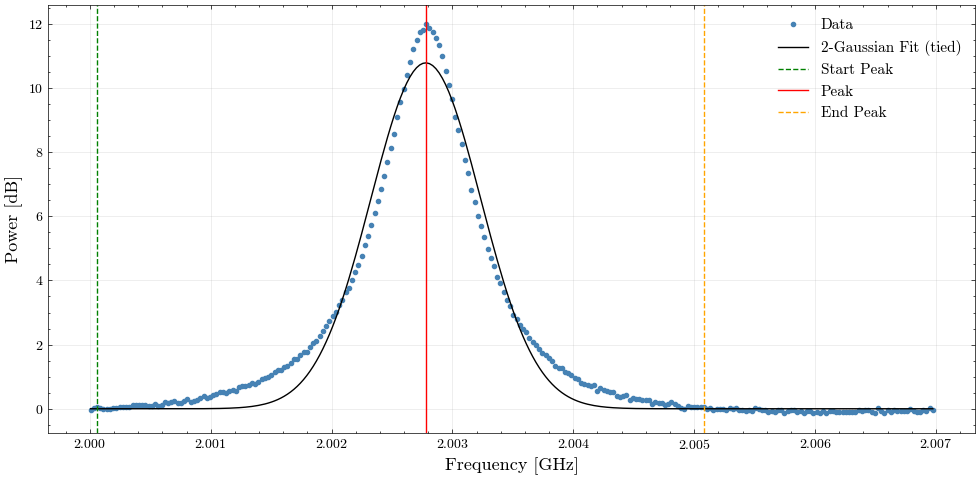

 At: [14:58:58]

          Date: 2023-03-11
          Start Frequency  : 2.000166 GHz 
          End Frequency    : 2.005106 GHz
          Peak Frequency   : 2.002756 GHz  | Power = 11.862 dB
          Corrupted Channels: 185.0
          Corrupted Bandwidth         : 4.94 MHz

          Gaussian FWHM    : 1070.12 kHz
          Number of Channels at FWHM: 41.0


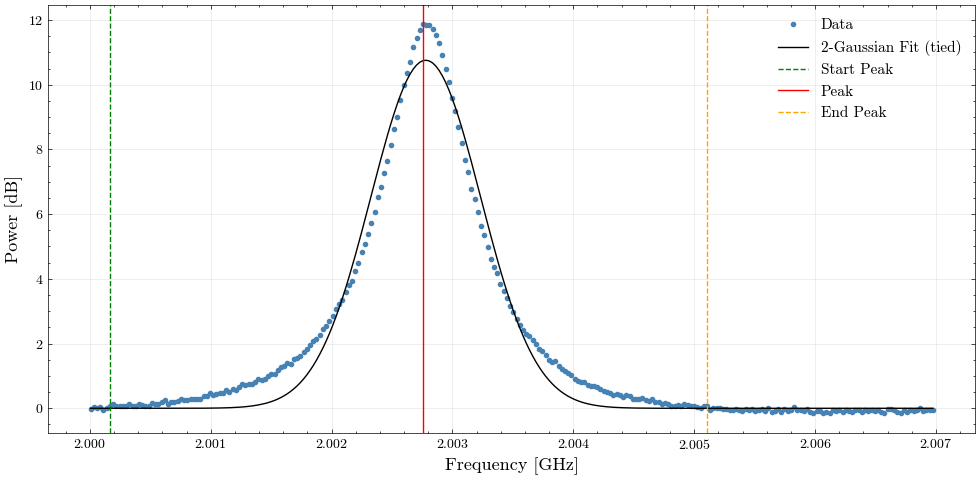

 At: [14:59:07]

          Date: 2023-03-11
          Start Frequency  : 2.000139 GHz 
          End Frequency    : 2.005106 GHz
          Peak Frequency   : 2.002783 GHz  | Power = 11.736 dB
          Corrupted Channels: 186.0
          Corrupted Bandwidth         : 4.97 MHz

          Gaussian FWHM    : 1064.71 kHz
          Number of Channels at FWHM: 40.0


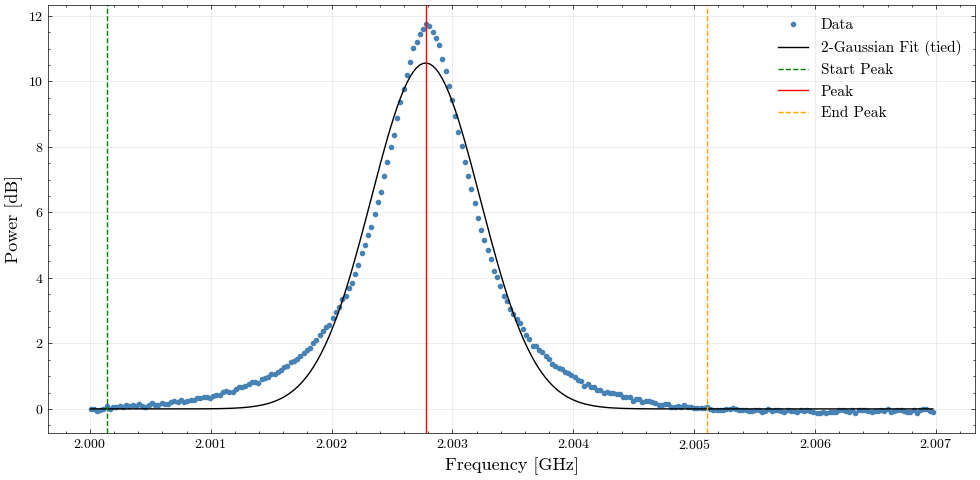

 At: [14:59:17]

          Date: 2023-03-11
          Start Frequency  : 2.000032 GHz 
          End Frequency    : 2.004972 GHz
          Peak Frequency   : 2.002810 GHz  | Power = 9.403 dB
          Corrupted Channels: 185.0
          Corrupted Bandwidth         : 4.94 MHz

          Gaussian FWHM    : 993.50 kHz
          Number of Channels at FWHM: 38.0


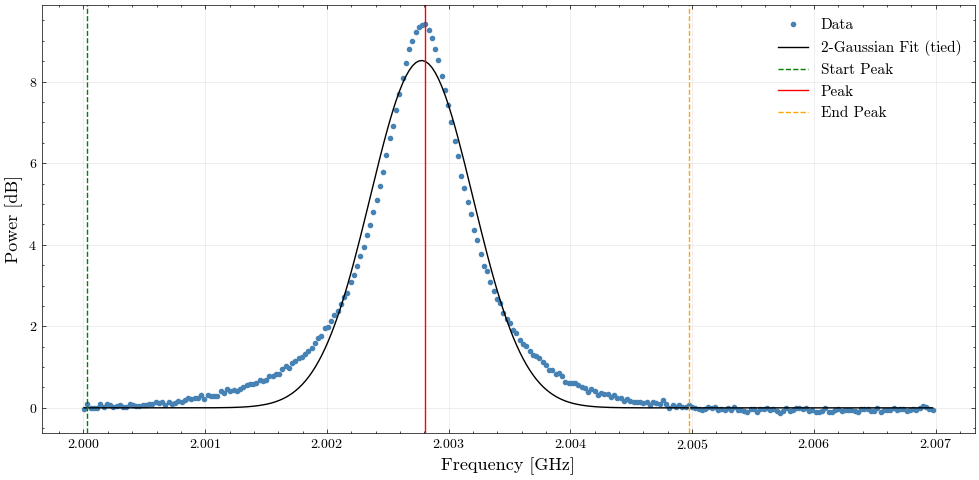

 At: [14:59:27]

          Date: 2023-03-11
          Start Frequency  : 2.000273 GHz 
          End Frequency    : 2.006975 GHz
          Peak Frequency   : 2.002783 GHz  | Power = 6.965 dB
          Corrupted Channels: 251.0
          Corrupted Bandwidth         : 6.70 MHz

          Gaussian FWHM    : 926.58 kHz
          Number of Channels at FWHM: 35.0


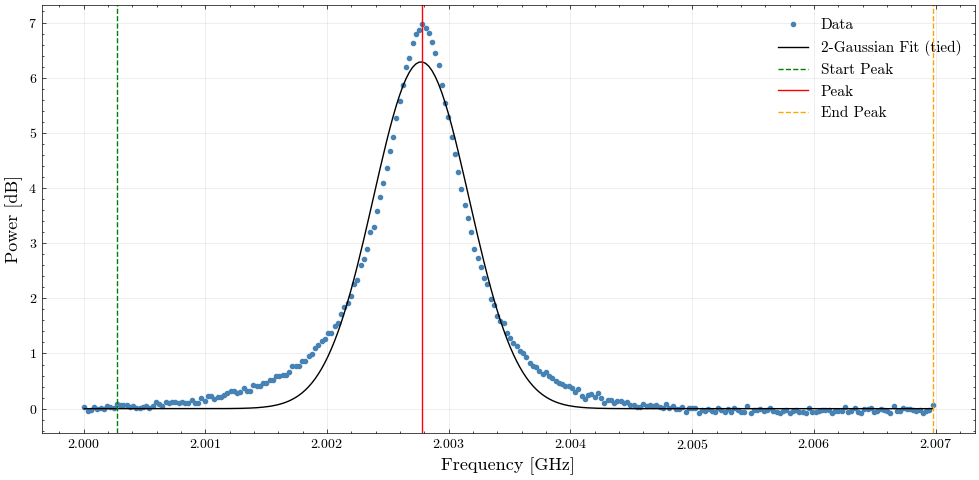

 At: [14:59:36]

          Date: 2023-03-11
          Start Frequency  : 2.000139 GHz 
          End Frequency    : 2.006895 GHz
          Peak Frequency   : 2.002810 GHz  | Power = 7.089 dB
          Corrupted Channels: 253.0
          Corrupted Bandwidth         : 6.76 MHz

          Gaussian FWHM    : 927.72 kHz
          Number of Channels at FWHM: 35.0


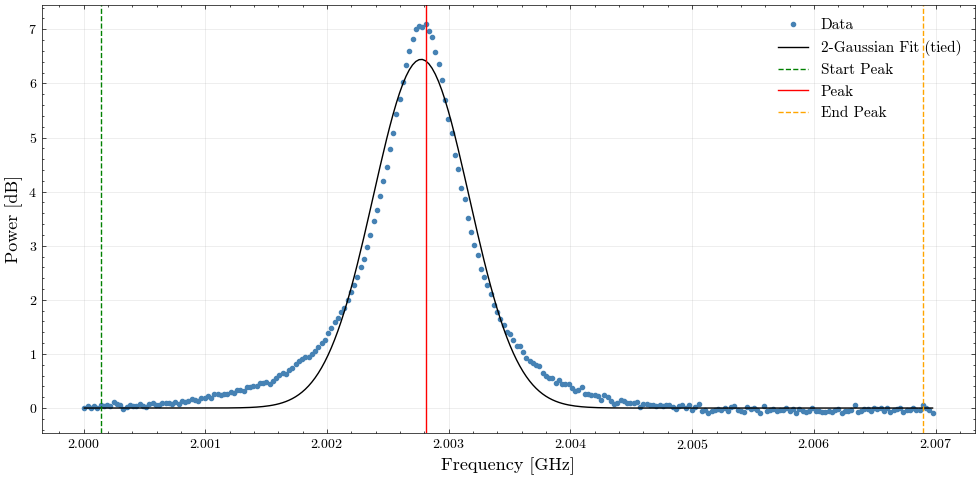

 At: [14:59:46]

          Date: 2023-03-11
          Start Frequency  : 2.000166 GHz 
          End Frequency    : 2.004946 GHz
          Peak Frequency   : 2.002810 GHz  | Power = 9.835 dB
          Corrupted Channels: 179.0
          Corrupted Bandwidth         : 4.78 MHz

          Gaussian FWHM    : 1006.27 kHz
          Number of Channels at FWHM: 38.0


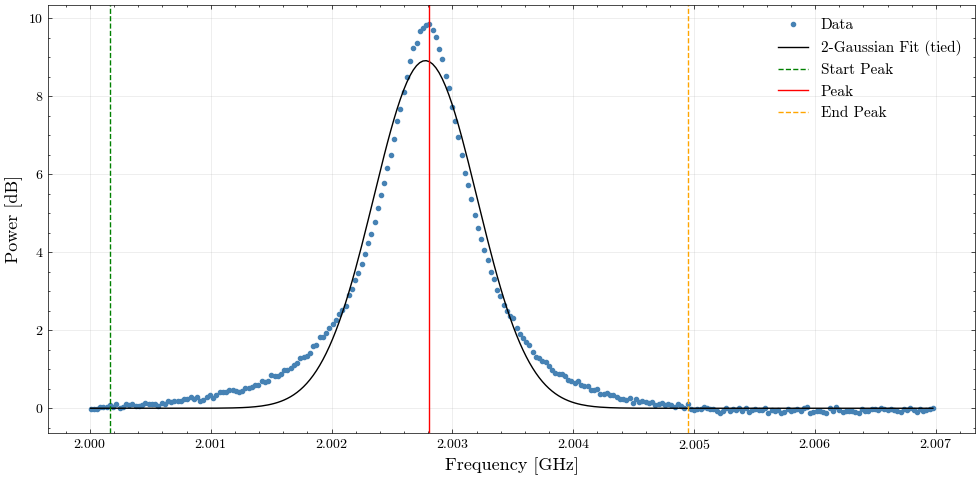

 At: [14:59:56]

          Date: 2023-03-11
          Start Frequency  : 2.000193 GHz 
          End Frequency    : 2.005106 GHz
          Peak Frequency   : 2.002810 GHz  | Power = 11.834 dB
          Corrupted Channels: 184.0
          Corrupted Bandwidth         : 4.91 MHz

          Gaussian FWHM    : 1069.23 kHz
          Number of Channels at FWHM: 41.0


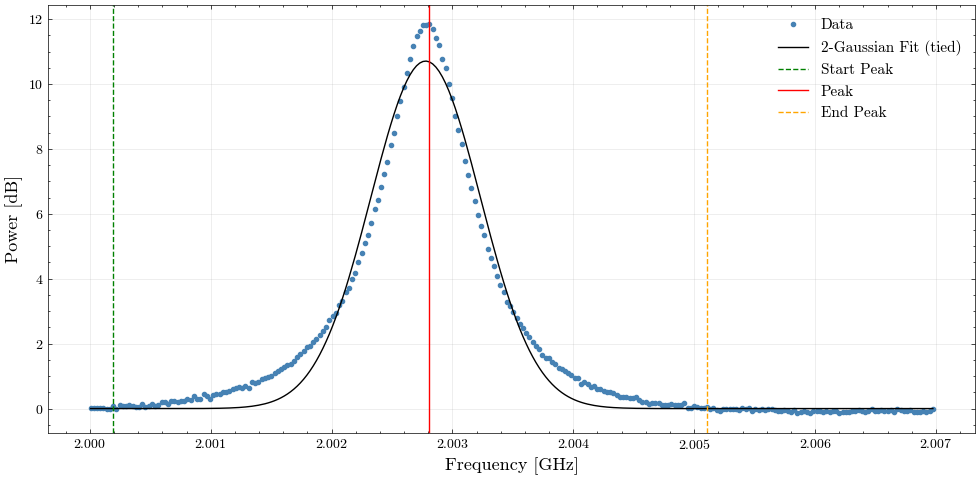

 At: [15:00:05]

          Date: 2023-03-11
          Start Frequency  : 2.000139 GHz 
          End Frequency    : 2.005133 GHz
          Peak Frequency   : 2.002783 GHz  | Power = 11.981 dB
          Corrupted Channels: 187.0
          Corrupted Bandwidth         : 4.99 MHz

          Gaussian FWHM    : 1075.45 kHz
          Number of Channels at FWHM: 41.0


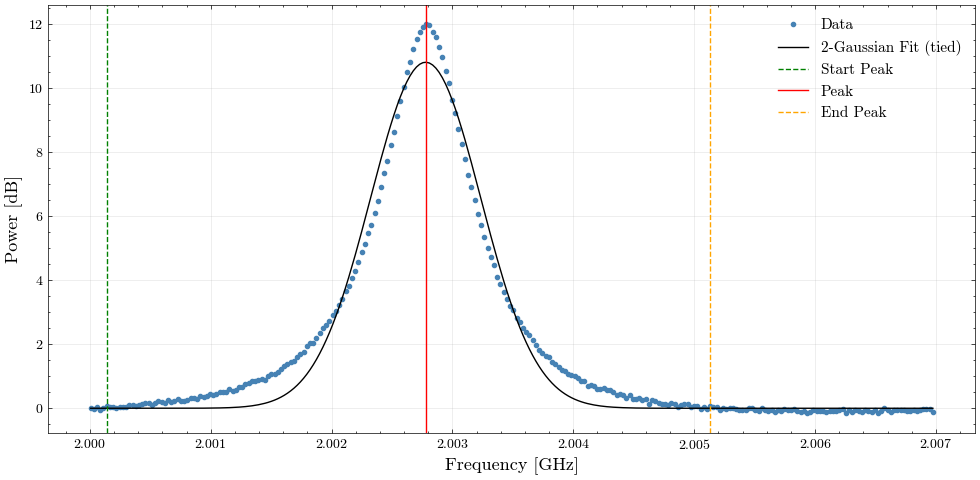

 At: [15:00:15]

          Date: 2023-03-11
          Start Frequency  : 2.000139 GHz 
          End Frequency    : 2.005239 GHz
          Peak Frequency   : 2.002783 GHz  | Power = 12.045 dB
          Corrupted Channels: 191.0
          Corrupted Bandwidth         : 5.10 MHz

          Gaussian FWHM    : 1079.13 kHz
          Number of Channels at FWHM: 41.0


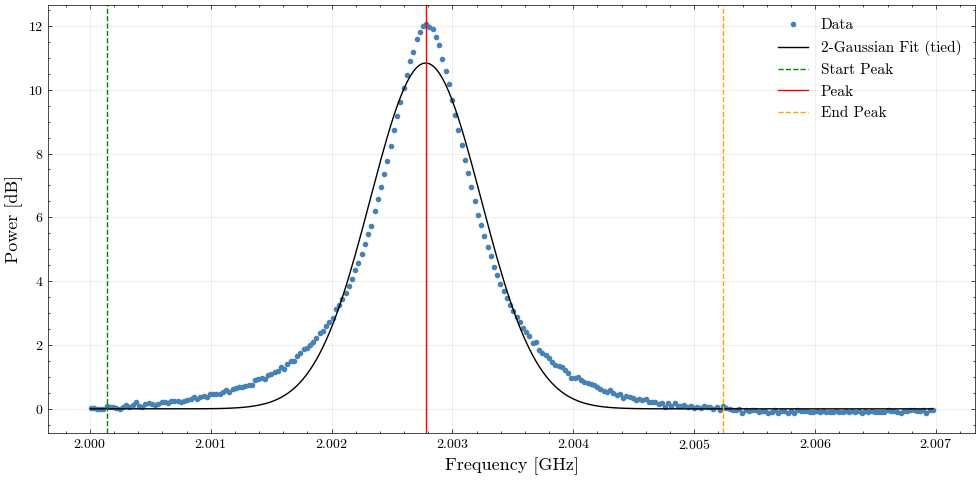

In [24]:
for t,f in enumerate(blocks1_det):
    print(f" At: [{block_time[t]}]")
    characterize_RFI_width(frequency[mask], sepc_block[t], tie=True, threshold=0.05)
    plt.show()
    #break

In [25]:
# Modified the function RFI characterization


def characterize_RFI_width1(freq, power, tie=False, threshold=0.05):
    """
    Characterize the frequency width and fit of an RFI peak.

    Parameters
    ----------
    freq : array-like
        Frequency values [GHz].
    power : array-like
        Baseline-corrected power spectrum (linear or dB).
    tie : bool, optional
        If True, fits two tied Gaussians (narrow + broad). 
        If False, fits a single Gaussian. Default = False.
    ax : matplotlib.axes.Axes, optional
        Existing matplotlib axis for plotting.
    threshold : float, optional
        Power threshold to define start/end of RFI. Default = 0.05.

    Returns
    -------
    results : dict
        Dictionary containing:
        - start_freq [GHz]
        - end_freq [GHz]
        - peak_freq [GHz]
        - peak_power
        - n_channels
        - bandwidth [MHz]
        - fwhm [kHz]
        - fitted_model (Astropy model)
    """

    # --- 1. Identify the RFI region above threshold ---
    above_threshold = np.where(power > threshold)[0]

    if len(above_threshold) == 0:
        print(" No significant RFI detected above threshold.")
        return None

    start_index, end_index = above_threshold[0], above_threshold[-1]
    start_freq = freq[start_index]
    end_freq = freq[end_index]

    # --- 2 Find peak position and amplitude ---
    peak_index = np.argmax(power)
    peak_freq = freq[peak_index]
    peak_power = power[peak_index]

    # --- 3 Basic RFI statistics ---
    delta_f = np.mean(np.diff(freq))  # spectral resolution
    n_channels = (end_freq - start_freq) / delta_f
    bandwidth = (end_freq - start_freq) * 1e3  # GHz → MHz


    
    print(f"Start Frequency  : {start_freq:.6f} GHz")
    print(f"End Frequency    : {end_freq:.6f} GHz")
    print(f"Peak Frequency   : {peak_freq:.6f} GHz  | Power = {peak_power:.3f} dB")
    print(f"Corrupted Channels: {n_channels:.1f}")
    print(f"Corrupted Bandwidth         : {bandwidth:.2f} MHz")

    # --- 4 Build initial Gaussian models ---
    amp_narrow = peak_power
    sigma_narrow = 5 * delta_f  # narrow Gaussian width guess

    amp_broad = amp_narrow / 5
    sigma_broad = 0.01  # GHz-scale broad Gaussian

    g_narrow = models.Gaussian1D(amplitude=amp_narrow, mean=peak_freq, stddev=sigma_narrow)
    g_broad = models.Gaussian1D(amplitude=amp_broad, mean=peak_freq, stddev=sigma_broad)

    # --- 5 Model fitting ---
    fitter = fitting.LMLSQFitter()

    if tie:
        # Tie both Gaussian centers
        def tie_means(model):
            return model.mean_0
        g_broad.mean.tied = tie_means
        model_init = g_narrow + g_broad
        fitted_model = fitter(model_init, freq, power)
        sigma = fitted_model.stddev_0.value + fitted_model.stddev_1.value
        label = "2-Gaussian Fit (tied)"
    else:
        fitted_model = fitter(g_narrow, freq, power)
        sigma = fitted_model.stddev.value
        label = "Single Gaussian Fit"

    fwhm = 2.355 * sigma  # convert σ → FWHM
    print(f"Gaussian FWHM    : {fwhm * 1e6:.2f} kHz")
    print(f"Number of Channels at FWHM: {np.ceil(fwhm/delta_f)}")

    # --- 6 Plotting ---
    # if ax is None:
    #     fig, ax = plt.subplots(figsize=(10, 5))

    # ax.plot(freq, power, '.', color='steelblue', label='Data')
    # ax.plot(freq, fitted_model(freq), 'black', lw=1, label=label)

    # # Mark important frequencies
    # ax.axvline(start_freq, color='green', ls='--', label='Start Peak')
    # ax.axvline(peak_freq, color='red', ls='-', label='Peak')
    # ax.axvline(end_freq, color='orange', ls='--', label='End Peak')

    # ax.set_xlabel("Frequency [GHz]", fontsize=13)
    # ax.set_ylabel("Power [dB]", fontsize=13)
    # ax.legend(fontsize=11)
    # ax.grid(alpha=0.3)

    # plt.tight_layout()


In [26]:
for t,f in enumerate(blocks1_det):
    print(" -------######------------------ ")
    print(f" At: [{block_time[t]}]")
    characterize_RFI_width1(frequency[mask], sepc_block[t], tie=True, threshold=0.05)
    

 -------######------------------ 
 At: [14:58:48]
Start Frequency  : 2.000059 GHz
End Frequency    : 2.005079 GHz
Peak Frequency   : 2.002783 GHz  | Power = 11.980 dB
Corrupted Channels: 188.0
Corrupted Bandwidth         : 5.02 MHz
Gaussian FWHM    : 1070.99 kHz
Number of Channels at FWHM: 41.0
 -------######------------------ 
 At: [14:58:58]
Start Frequency  : 2.000166 GHz
End Frequency    : 2.005106 GHz
Peak Frequency   : 2.002756 GHz  | Power = 11.862 dB
Corrupted Channels: 185.0
Corrupted Bandwidth         : 4.94 MHz
Gaussian FWHM    : 1070.12 kHz
Number of Channels at FWHM: 41.0
 -------######------------------ 
 At: [14:59:07]
Start Frequency  : 2.000139 GHz
End Frequency    : 2.005106 GHz
Peak Frequency   : 2.002783 GHz  | Power = 11.736 dB
Corrupted Channels: 186.0
Corrupted Bandwidth         : 4.97 MHz
Gaussian FWHM    : 1064.71 kHz
Number of Channels at FWHM: 40.0
 -------######------------------ 
 At: [14:59:17]
Start Frequency  : 2.000032 GHz
End Frequency    : 2.004972 GH

# Explor the backgroud over observation time

-> Investigate the impact of the increase of the backgroud on the detrending

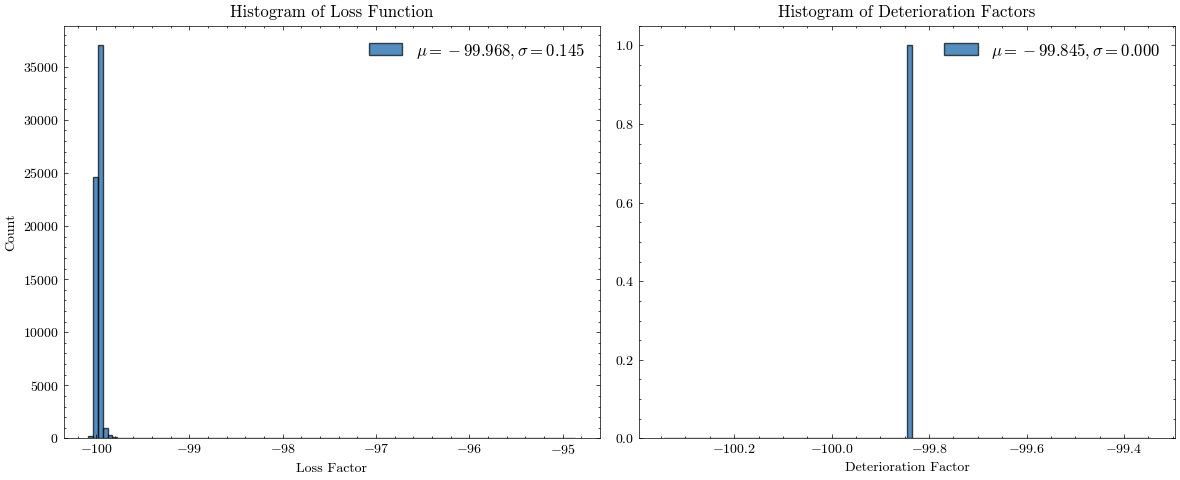

In [38]:

for t,f in enumerate(blocks1):
        

    # Step 1: define the baseli fitting
    baseline_fitter = Baseline(x_data=frequency)
    bkg, params = baseline_fitter.asls(blocks1[t], lam=1e7, p=0.03)

    # Step 2: evaluate residual signal after baseline correction
    baseli_correction = blocks1[t] - bkg

    ## Relative Loss Function
    loss_func = ((baseli_correction-blocks1[t])/blocks1[t])*100 

    
    ## Relative Deterioration of the Spectral
    sigma_residual = np.sqrt(np.nanmean(baseli_correction**2))
    sigma_noise = np.sqrt(np.nanmean(bkg**2))

    deterioration = ((sigma_residual-sigma_noise)/sigma_noise)*100


    fig, ax = plt.subplots(1, 2, figsize=(12, 5))

    # -------------------------------
    # Histogram 1: Loss Factor
    # -------------------------------
    ax[0].hist(loss_func, bins=100, alpha=0.7, edgecolor='black', label=f'$\mu= {np.mean(loss_func):.3f}, \sigma ={np.std(loss_func):.3f}$')
    # ax[0].axvline(loss_opt, color='red', linestyle='--', linewidth=2,
    #             label=f"Optimised = {loss_opt:.3f}")\
    ax[0].set_title("Histogram of Loss Function")
    ax[0].set_xlabel("Loss Factor")
    ax[0].set_ylabel("Count")
    ax[0].legend(fontsize=12)

    # -------------------------------
    # Histogram 2: Deterioration Factor
    # -------------------------------
    ax[1].hist(deterioration, bins=100, alpha=0.7, edgecolor='black', label=f'$\mu= {np.mean(deterioration):.3f}, \sigma ={np.std(deterioration):.3f}$')
    # ax[1].axvline(det_opt, color='red', linestyle='--', linewidth=2,
    #             label=f"Optimised = {det_opt:.3f}")
    ax[1].set_title("Histogram of Deterioration Factors")
    ax[1].set_xlabel("Deterioration Factor")
    ax[1].legend(fontsize=12)

    plt.tight_layout()
    plt.show()


    break




### Within each block we have to:
1 - get one-dimension sigma
2 - 

In [37]:
blocks1[0].shape

(63877,)

In [28]:
loss_func.shape

(63877,)

In [29]:
deterioration = ((np.std(baseli_correction)-np.std(bkg))/np.std(bkg))*100


In [30]:
baseli_correction

array([0.24031067, 0.27760315, 0.23301697, ..., 0.37319946, 0.36621094,
       0.37948608], dtype=float32)

In [31]:
bkg

array([216.75424, 216.75096, 216.7477 , ..., 184.40945, 184.40494,
       184.4004 ], dtype=float32)

In [32]:

rms_values = []
residuals_list = []

for t, block in enumerate(blocks1):

    # --- Fit baseline ---
    baseline_fitter = Baseline(x_data=frequency)
    bkg, params = baseline_fitter.asls(block, lam=1e7, p=0.02)

    # --- Residual spectrum ---
    residual = block - bkg
    residuals_list.append(residual)

    # --- Compute RMS ---
    rms = np.sqrt(np.mean(residual**2))
    rms_values.append(rms)

    #break


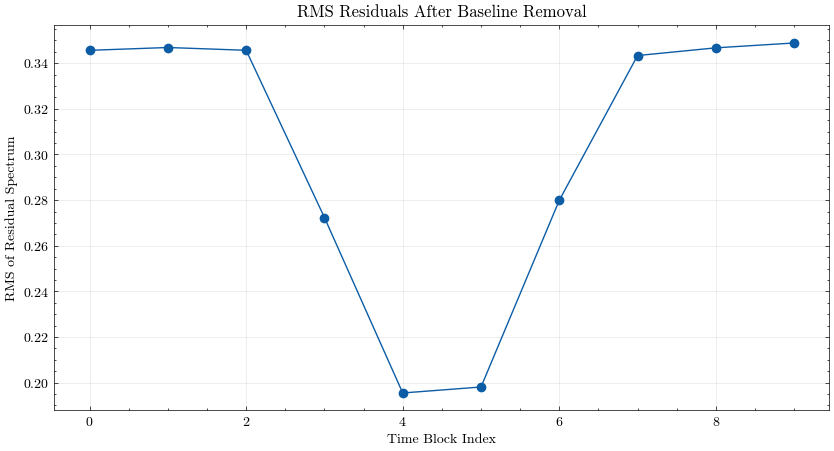

In [33]:
plt.figure(figsize=(10,5))
plt.plot(range(len(rms_values)), rms_values, marker='o')
plt.xlabel("Time Block Index")
plt.ylabel("RMS of Residual Spectrum")
plt.title("RMS Residuals After Baseline Removal")
plt.grid(alpha=0.3)
plt.show()


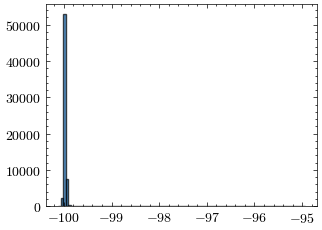

In [34]:

for t,f in enumerate(blocks1):
        

    # Step 1: define the baseli fitting
    baseline_fitter = Baseline(x_data=frequency)
    bkg, params = baseline_fitter.asls(blocks1[t], lam=1e7, p=0.05)

    baseli_correction = blocks1[t] - bkg
    loss_func = ((baseli_correction-blocks1[t])/blocks1[t])*100 

    plt.hist(loss_func, bins=100, alpha=0.7, edgecolor='black')

    break


In [35]:
(blocks1[0]-baseli_correction)/blocks1[0]

array([0.99904954, 0.9988771 , 0.99908155, ..., 0.99839824, 0.9984381 ,
       0.99836856], dtype=float32)

In [36]:
baseli_correction

array([0.2062378 , 0.24369812, 0.19927979, ..., 0.29597473, 0.28858948,
       0.30145264], dtype=float32)